# Gemma 3 4B — Custom Fine-tune on ACLEDA Q&A (Khmer)

**Task:** fine-tune `unsloth/gemma-3-4b-it` with LoRA / PEFT so it answers questions about ACLEDA Bank products (cards, accounts, loans, mobile banking) in Khmer — using **your** dataset, `dataasilida_cleaned.csv`.

**Homework objectives covered**
1. **Course summary** — LLM fine-tuning workflow, Gemma 3, LoRA, PEFT, dataset preparation (§1).
2. **Notebook configuration** — every hyperparameter lives in one `CONFIG` dict (§0). Change it there, re-run from §2.
3. **Loss analysis** — training loss **and** validation loss are both logged, plotted, and interpreted (§5).
4. **Practical experiment** — the same questions are asked to the base model **before** training and to the fine-tuned model **after** training, and compared with the gold answers (§3, §6). The old robot-command run is the baseline to compare against (§8).



## §0 — Setup

In [1]:
%%capture
# Install Unsloth + training stack. Run once, then RESTART the runtime/kernel.
!pip install -q unsloth
!pip install -q trl peft accelerate bitsandbytes datasets transformers matplotlib
print("Install done — restart the runtime/kernel now, then continue from the next cell.")

In [37]:
# ── CONFIG: change hyperparameters HERE only. Every cell below reads from this dict. ──
CONFIG = {
    # --- files ---
    "original_csv_file": "/content/drive/MyDrive/Colab Notebooks/Year 5/ADV/dataasilida_cleaned.csv",  # path to Google Drive
    "csv_file": "dataasilida_fixed.csv",             # repaired copy, written by §2
    "output_dir": "outputs",
    "lora_dir": "gemma-3-4b-aclede-qa-lora",
    "merged_dir": "gemma-3-4b-aclede-qa-merged",
    # --- model ---
    "model_name": "unsloth/gemma-3-4b-it",
    "max_seq_length": 2048,   # longest answer is 2,826 chars; 2048 tokens is safe headroom
    "load_in_4bit": True,     # 4-bit quantisation: fits a T4, ~6 GB peak in the original run
    # --- LoRA / PEFT ---
    "lora_r": 16,             # original used 8; 16 gives a little more capacity for long Khmer answers
    "lora_alpha": 16,         # keep alpha == r (scaling = alpha / r = 1)
    "lora_dropout": 0.0,
    # --- data split ---
    "val_fraction": 0.10,     # 10% of *questions* held out for validation
    "seed": 3407,
    # --- training ---
    "num_train_epochs": 3,
    "max_steps": -1,          # -1 = train for num_train_epochs; set e.g. 60 for a quick smoke test
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 4,   # effective batch = 2 x 4 = 8
    "learning_rate": 2e-4,    # standard for LoRA on a 4B model; use 2e-5 for very long runs
    "warmup_steps": 5,
    "weight_decay": 0.01,
    "lr_scheduler_type": "linear",
    "logging_steps": 5,
    "eval_steps": 20,         # evaluate (validation loss) every 20 steps
    "save_steps": 20,
    # --- generation (before/after test) ---
    "test_max_new_tokens": 384,   # answers are long (median 231 chars); 384 tokens avoids cutting them off
    # --- Hugging Face ---
    "hf_username": "mondolreal",   # <-- Updated with your HF username!
    "hf_repo_lora": "gemma-3-4b-it-aclede-qa-lora",
    "hf_repo_merged": "gemma-3-4b-it-aclede-qa-merged",
    "push_to_hub": True,     # Enabled so that your LoRA adapter will upload to Hugging Face
}
print("CONFIG loaded. Effective batch size:",
      CONFIG["per_device_train_batch_size"] * CONFIG["gradient_accumulation_steps"])

CONFIG loaded. Effective batch size: 8


In [3]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch:", torch.__version__)
else:
    raise SystemExit("No GPU found — run this notebook on Colab (T4 GPU) or another GPU machine.")

CUDA available: True
GPU: Tesla T4
PyTorch: 2.14.1+cu130


## §1 — Course summary: what fine-tuning is

**The workflow, in one line:** base model → prepared dataset → tokenised chat text → LoRA training (SFT) → validation loss → inference test → save / push to Hugging Face.

| Step | What happens | Where in this notebook |
|---|---|---|
| 1. Base model | Start from Gemma 3 4B **instruction-tuned** (`-it`): it already chats, we teach it ACLEDA facts + answer style | §2 model load |
| 2. Dataset prep | `input` (question) / `output` (answer) pairs → `user` / `assistant` messages → Gemma chat template text | §2 data prep |
| 3. PEFT / LoRA | Freeze the 4B base weights; train only small low-rank adapter matrices | §2 LoRA cell |
| 4. SFT training | Supervised fine-tuning: predict the answer tokens, loss = cross-entropy | §4 trainer |
| 5. Evaluation | Validation loss on held-out questions + before/after answers | §5, §6 |
| 6. Save / share | LoRA adapter (small) or merged full model → Hugging Face Hub | §7 |

**Gemma 3 (4B-it).** Google's open 4B-parameter instruction-tuned model. Multimodal (text + images) — here we use **text only** (`finetune_vision_layers=False`). It was trained to follow the `<start_of_turn>user … <end_of_turn><start_of_turn>model …` chat format, which is why the dataset must be rendered in exactly that format.

**LoRA / PEFT.** Full fine-tuning would update all ~4,000,000,000 weights — too much memory for a T4. PEFT (Parameter-Efficient Fine-Tuning) freezes the base model and trains only LoRA adapters: for each target weight matrix `W`, learn a low-rank update `W + B·A`, where `A` and `B` are small. Rank `r` = the size of that bottleneck:
- `r = 8` in the original run → **14,901,248 trainable parameters (0.37%)**.
- `r = 16` here → roughly double that, still **under 1%** of the model. The trainer prints the exact number.
- Bigger `r` = more capacity, but more overfitting risk on a small dataset (519 pairs). Smaller `r` = safer, but may underfit long answers.

**Dataset preparation.** SFT needs (question, answer) pairs in the model's chat format. The raw CSV is *not* ready: its header is broken and 7 rows are malformed (§2 fixes both), duplicate questions exist, and there is no validation split. Cleaning + splitting is part of the homework, not a chore before it.

## §2 — Load the model + LoRA adapters

In [4]:
from unsloth import FastModel

model, tokenizer = FastModel.from_pretrained(
    model_name=CONFIG["model_name"],
    max_seq_length=CONFIG["max_seq_length"],
    load_in_4bit=CONFIG["load_in_4bit"],  # 4-bit quantisation to reduce memory
    load_in_8bit=False,
    full_finetuning=False,
    # token = "hf_...",  # only needed for gated models; Gemma needs licence acceptance on HF instead
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1124 09:09:53.365000 506 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 09:09:53.453000 506 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.10: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [5]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers=False,    # text only
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=CONFIG["lora_r"],
    lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=CONFIG["lora_dropout"],
    bias="none",
    random_state=CONFIG["seed"],
)
model.print_trainable_parameters()

trainable params: 29,802,496 || all params: 4,329,881,968 || trainable%: 0.6883


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## §2 (continued) — Data preparation: your ACLEDA dataset

**What the file actually contains (checked 2026-11-24):**
- **521 data rows**, Khmer Q&A about ACLEDA Bank: debit/credit cards (JCB, UnionPay, Visa, virtual cards), accounts, loans, ABA Mobile / e-commerce, and National Bank of Cambodia topics.
- Question length: median **57 chars**, max 203. Answer length: median **231 chars**, 90th percentile 684, max **2,826** — much longer than the old robot dataset's short JSON outputs.
- **2 exact duplicate pairs** (same question + same answer) and **16 questions with several *different* answers** (e.g. the generic question "how big is the loan and how long?" has a different answer per loan type). Those are kept, but grouped so the same question never appears on both sides of the train/val split.

**Two defects in the file — this is why `load_dataset("csv", ...)` cannot be used directly:**
1. The header line is the single quoted field `"input,output"`, not two columns. Pandas/`datasets` then read **1 column** and put the answer in an unnamed column.
2. **7 rows** are a single quoted field holding `question ,answer` (6 rows) or `question \n answer` (1 row) instead of two fields. They would be lost or mis-read.

The cell below repairs both, drops nothing it can repair (0 rows dropped), removes the 2 exact duplicates, and writes the clean file `dataasilida_fixed.csv`.

In [10]:
import csv
import re
from datasets import Dataset

def load_qa_pairs(csv_path):
    """Read input/output pairs, repairing the two known defects (see markdown above)."""
    pairs, dropped = [], []
    with open(csv_path, newline="", encoding="utf-8") as f:
        rows = list(csv.reader(f))
    for i, row in enumerate(rows[1:], start=2):  # header is line 1
        if len(row) == 2:
            q, a = row[0].strip(), row[1].strip()
        elif len(row) == 1:
            s = row[0].strip()
            if " ," in s:
                q, a = (part.strip() for part in s.split(" ,", 1))
            else:
                m = re.search(r"\?", s)
                if not m:
                    dropped.append((i, s[:80]))
                    continue
                q = s[: m.end()].strip()
                a = s[m.end():].replace("\\n", " ").replace("\u200b", "").strip()
        else:
            dropped.append((i, f"{len(row)} fields"))
            continue
        if q and a:
            pairs.append({"input": q, "output": a})
        else:
            dropped.append((i, "empty question or answer"))
    return pairs, dropped

pairs, dropped = load_qa_pairs(CONFIG["original_csv_file"])
print(f"Raw data rows (excluding header): {len(pairs) + len(dropped)}")
print(f"Usable pairs after repair: {len(pairs)}")
print(f"Dropped rows: {len(dropped)} {dropped}")

seen, unique_pairs = set(), []
for p in pairs:
    key = (p["input"], p["output"])
    if key not in seen:
        seen.add(key)
        unique_pairs.append(p)
pairs = unique_pairs
print(f"After removing exact duplicate pairs: {len(pairs)}")

with open(CONFIG["csv_file"], "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["input", "output"])
    w.writeheader()
    w.writerows(pairs)
print(f"Wrote repaired CSV: {CONFIG['csv_file']}")

Raw data rows (excluding header): 521
Usable pairs after repair: 521
Dropped rows: 0 []
After removing exact duplicate pairs: 519
Wrote repaired CSV: dataasilida_fixed.csv


In [11]:
import statistics

qs = [p["input"] for p in pairs]
print(f"Total pairs: {len(pairs)}")
print(f"Unique questions: {len(set(qs))}")
print(f"Questions with more than one different answer: "
      f"{sum(1 for q in set(qs) if qs.count(q) > 1)}")
in_len = [len(p["input"]) for p in pairs]
out_len = [len(p["output"]) for p in pairs]
print(f"Question length (chars): median {statistics.median(in_len):.0f}, max {max(in_len)}")
print(f"Answer length (chars): median {statistics.median(out_len):.0f}, "
      f"p90 {sorted(out_len)[int(len(out_len) * 0.9)]}, max {max(out_len)}")
print(f"Answers longer than 1000 chars: {sum(1 for x in out_len if x > 1000)}")
for p in pairs[:3]:
    print("\nQ:", p["input"])
    print("A:", p["output"][:200], "...")

Total pairs: 519
Unique questions: 481
Questions with more than one different answer: 16
Question length (chars): median 57, max 203
Answer length (chars): median 231, p90 684, max 2826
Answers longer than 1000 chars: 16

Q: តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី
A: ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹ ...

Q: តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូវអត្ថប្រយោជន៍អ្វីខ្លះ
A: លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ដូចខាងក្រោម៖ -អាចដកសាច់ប្រាក់បានឆាប់រហ័សពីគ្រប់ម៉ាស៊ីន អេធីអឹម ទាំងអស់ដែលមានស្លាកសញ្ញា ចេស៊ីប៊ី ធម្មតា នៅក្នុង និងក្រៅប្រ ...

Q: តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន
A: លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បានដោយគ្រាន់តែ បើកគណនីមួយនៅធនាគារ អេស៊ីលីដា សាខាណាមួយដែលនៅជិតលោកអ្នកបំផុត ហើយគណនីនោះអាចជា គណនីបញ្ញើសំចៃ គ

In [12]:
# Grouped train/validation split: split by QUESTION, not by row.
# Otherwise the 16 questions with several answers would leak across the
# split (same question in train and val) and validation loss would look
# better than it really is.
import random
from collections import defaultdict

by_question = defaultdict(list)
for p in pairs:
    by_question[p["input"]].append(p)

questions = list(by_question)
random.Random(CONFIG["seed"]).shuffle(questions)
n_val_q = int(round(len(questions) * CONFIG["val_fraction"]))

train_pairs = [p for q in questions[n_val_q:] for p in by_question[q]]
val_pairs = [p for q in questions[:n_val_q] for p in by_question[q]]
assert not (set(p["input"] for p in train_pairs) & set(p["input"] for p in val_pairs))
print(f"Questions: {len(questions)} total -> {len(questions) - n_val_q} train, {n_val_q} val")
print(f"Rows: {len(train_pairs)} train, {len(val_pairs)} val")
print(f"Steps per epoch at effective batch 8: {len(train_pairs) // 8} "
      f"-> {CONFIG['num_train_epochs']} epochs = about {len(train_pairs) // 8 * CONFIG['num_train_epochs']} steps")

Questions: 481 total -> 433 train, 48 val
Rows: 470 train, 49 val
Steps per epoch at effective batch 8: 58 -> 3 epochs = about 174 steps


In [13]:
# Format each pair as Gemma-3 chat text:
# <bos><start_of_turn>user\nQUESTION<end_of_turn>\n<start_of_turn>model\nANSWER<end_of_turn>\n
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(tokenizer, chat_template="gemma-3")

def formatting_prompts_func(examples):
    texts = []
    for instruction, output in zip(examples["input"], examples["output"]):
        messages = [
            {"role": "user", "content": instruction.strip()},
            {"role": "assistant", "content": output.strip()},
        ]
        texts.append(tokenizer.apply_chat_template(messages, add_generation_prompt=False, tokenize=False))
    return {"text": texts}

train_ds = Dataset.from_dict({"input": [p["input"] for p in train_pairs],
                              "output": [p["output"] for p in train_pairs]})
val_ds = Dataset.from_dict({"input": [p["input"] for p in val_pairs],
                            "output": [p["output"] for p in val_pairs]})
train_ds = train_ds.map(formatting_prompts_func, batched=True)
val_ds = val_ds.map(formatting_prompts_func, batched=True)
print(train_ds)
print(val_ds)
print("\n--- Example formatted text (train[0]) ---")
print(train_ds["text"][0][:600])

Map:   0%|          | 0/470 [00:00<?, ? examples/s]

Map:   0%|          | 0/49 [00:00<?, ? examples/s]

Dataset({
    features: ['input', 'output', 'text'],
    num_rows: 470
})
Dataset({
    features: ['input', 'output', 'text'],
    num_rows: 49
})

--- Example formatted text (train[0]) ---
<bos><start_of_turn>user
របៀប Login ចូលទៅប្រើប្រាស់កម្មវិធីនេះ<end_of_turn>
<start_of_turn>model
ដើម្បី Login អ្នកត្រូវតែជាអតិថិជនរបស់ធនាគារ ABA ។ ប្រសិនបើអ្នកមានកាត ABA ហើយបានប្រើលេខទូរស័ព្ទរបស់អ្នកដើម្បីចុះឈ្មោះជាមួយយើងនោះ អ្នកអាចគ្រាន់តែទាញយកកម្មវិធីនេះរួចអនុវត្តតាមការណែនាំជាការស្រេច។ប្រសិនជាអ្នកជាអតិថិជនរបស់ធនាគារ ABA តែលោកអ្នកពុំមានកាតនោះទេ គ្រាន់តែយកទូរស័ព្ទដៃ iPhone ឬ Android smartphone របស់អ្នកអញ្ជើញទៅធនាគារ ABA ដែលនៅជិតលោកអ្នកបំផុត ដើម្បីចុះឈ្មោះប្រើប្រាស់សេវាកម្មនេះ។ បុគ្គលិករបស់យើងខ្ញុំនឹងណែនាំលោកអ្នកអំពីវិធីចុះឈ្មោះ។<end_of_turn>



In [14]:
# Sanity check: does anything get cut off at max_seq_length?
def token_len(text):
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

for name, ds in [("train", train_ds), ("val", val_ds)]:
    lens = [token_len(t) for t in ds["text"]]
    print(f"{name}: tokens median {statistics.median(lens):.0f}, max {max(lens)}, "
          f"over {CONFIG['max_seq_length']}: {sum(1 for x in lens if x > CONFIG['max_seq_length'])}")

train: tokens median 1, max 1, over 2048: 0
val: tokens median 1, max 1, over 2048: 0


## §3 — Baseline: ask the *base* model first (before training)

Objective 4 needs a real comparison, not a feeling. So we ask the **untrained** base model 3 held-out validation questions now, save its answers, and ask the **same** questions again after training (§6). Greedy decoding (`do_sample=False`) is used so the same question always gives the same answer — otherwise you could not tell training apart from sampling luck.

The 3 questions are validation questions with short gold answers, so the comparison fits on screen.

In [15]:
def generate_answer(question, max_new_tokens=None):
    """Ask the (current) model one question; return only the generated answer text."""
    messages = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens or CONFIG["test_max_new_tokens"],
            do_sample=False,  # greedy: same question -> same answer, so before/after is comparable
        )
    generated = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()

# Validation questions with short gold answers — good for a readable comparison.
TEST_QUESTIONS = [p["input"] for p in val_pairs if len(p["output"]) < 400][:3]
print("Test questions:")
for q in TEST_QUESTIONS:
    print("-", q)

Test questions:
- តើអ៉ីអនកាតម៉ូបាលគឺជាអ្វី
- តើសេវាភតិសន្យាហិរញ្ញវត្ថុមានប្រភេទរូបិយប័ណ្ណអ្វីខ្លះ
- តើការចុះឈ្មោះប្រើប្រាស់ អ៉ីអនវ៉លឡេត មានកម្រៃសេវាប៉ុន្មាន


In [16]:
BASELINE_OUTPUTS = {}
for q in TEST_QUESTIONS:
    ans = generate_answer(q)
    BASELINE_OUTPUTS[q] = ans
    print("Q:", q)
    print("BASE:", ans)
    print()

Q: តើអ៉ីអនកាតម៉ូបាលគឺជាអ្វី
BASE: អ៉ីអនកាតម៉ូបាល (eNKey Mobile) គឺជាបច្ចេកវិជ្ជារបស់ក្រុមហ៊ុន Cambodian e-Government Authority (eGA) ដែលមានគោលប tujuan យ៉ាងសំខាន់គឺ ធ្វើឱ្យការប្រើប្រាស់ប័ណ្ណអេឡិចត្រូនិច (e-ID) ង่ายស្រួល និង సుវត្តិសម្រាប់ប្រជាជនកម្ពុជា។ 

ខាងក្រោមនេះជាការបកស្រាយយ៉ាងវែងឆ្កួតអំពីអ៉ីអនកាតម៉ូបាល:

**1. គោលបំណង និង មុខងារសំខាន់:**

*   **ការប្រើប្រាស់ប័ណ្ណអេឡិចត្រូនិច (e-ID):** អ៉ីអនកាតម៉ូបាល ផ្តល់នូវវិធីសាស្រ្តថ្មីមួយក្នុងការប្រើប្រាស់ប័ណ្ណអេឡិចត្រូនិច ដើម្បីធ្វើការផ្ទេរប័ណ្ណ, ចូលដំណើរការកម្មវិធីរដ្ឋបក្ស, និងធ្វើការិយាល័យបច្ចេកទេសផ្សេងៗ តាមរយៈកម្មវិធីមួយប៉ុណ្ណោះ។
*   **ការផ្ទេរប័ណ្ណ (e-Card Transfer):** អាចផ្ទេរប័ណ្ណអេឡិចត្រូនិចពីប័ណ្ណកាត (physical card) ទៅប័ណ្ណលើទូរស័ព្ទបានយ៉ាង సుវត្តិ។
*   **ការផ្ទេរប័ណ្ណដោយស្វត tự:** អាចផ្ទេរប័ណ្ណអេឡិចត្រូនិចដោយខ្លួនឯងបាន ដោយមិនចាំបាច់រឿងរ៉ាវច្រើន។
*   **ការប្រើប្រាស់ប័ណ្ណលើទូរស័ព្ទ:** អាចប្រើប្រាស់ប័ណ្ណអេឡិចត្រូនិចលើទូរស័ព្ទ Android គ្រប់ប្រភេទ។
*   **ការការពារសុវត្តិភាព:** ប្រើ

Q: តើសេវាភតិសន្យាហិរញ្ញវត្ថុមានប្រភេទរូបិយប័ណ្ណអ្វីខ្លះ
B

## §4 — Training configuration

| Hyperparameter | Value here | What it does | If it is too high | If it is too low |
|---|---|---|---|---|
| `learning_rate` | 2e-4 | Step size of each weight update | Loss jumps / diverges, model forgets | Learns too slowly, underfits |
| `num_train_epochs` | 3 | Full passes over the 470 train rows | Memorizes train set → overfitting | Underfits, answers stay generic |
| `per_device_train_batch_size` | 2 | Rows per GPU step | Out of memory on a T4 | Noisy updates (partly fixed by accumulation) |
| `gradient_accumulation_steps` | 4 | Steps averaged before one update; effective batch = 2×4 = **8** | Slower per update | Noisy, unstable loss |
| `lora_r` / `lora_alpha` | 16 / 16 | LoRA bottleneck size / scaling | Overfits a 519-row dataset | Cannot learn long answers |
| `weight_decay` | 0.01 | L2 penalty on weights | Underfits | Overfits |
| `warmup_steps` | 5 | Steps with LR rising from 0 | — | Early loss spike |
| `lr_scheduler_type` | linear | LR decays linearly to 0 | — | — |
| `max_seq_length` | 2048 | Texts longer than this are truncated | Wastes memory | Long answers get cut off |
| `eval_steps` | 20 | Validation loss every 20 steps | Slower training | You miss the overfitting point |
| `optim` | adamw_8bit | 8-bit AdamW, saves memory | — | — |

**Try changing one thing at a time** and re-running: e.g. `num_train_epochs = 1` vs `3`, or `learning_rate = 1e-4` vs `2e-4`, then compare the §5 loss curves and the §6 answers. That is the experiment in Objective 4.

In [17]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# NOTE: this is the cell the original notebook crashed in.
# Fix: train_dataset is train_ds (a Dataset), NOT the whole DatasetDict.
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    dataset_text_field="text",
    dataset_num_proc=2,
    packing=False,  # packing mixes examples; keep False so val loss stays per-example
    args=TrainingArguments(
        per_device_train_batch_size=CONFIG["per_device_train_batch_size"],
        per_device_eval_batch_size=CONFIG["per_device_train_batch_size"],
        gradient_accumulation_steps=CONFIG["gradient_accumulation_steps"],
        warmup_steps=CONFIG["warmup_steps"],
        num_train_epochs=CONFIG["num_train_epochs"],
        max_steps=CONFIG["max_steps"],
        learning_rate=CONFIG["learning_rate"],
        fp16=not is_bfloat16_supported(),
        bf16=is_bfloat16_supported(),
        logging_steps=CONFIG["logging_steps"],
        eval_strategy="steps",       # <-- this is what creates validation loss
        eval_steps=CONFIG["eval_steps"],
        save_strategy="steps",
        save_steps=CONFIG["save_steps"],
        save_total_limit=2,
        load_best_model_at_end=True,  # keep the checkpoint with the lowest val loss
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        optim="adamw_8bit",
        weight_decay=CONFIG["weight_decay"],
        lr_scheduler_type=CONFIG["lr_scheduler_type"],
        seed=CONFIG["seed"],
        output_dir=CONFIG["output_dir"],
        report_to="none",
    ),
)
print("Trainer ready.")

`torch_dtype` is deprecated! Use `dtype` instead!


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/470 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/49 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Trainer ready.


In [18]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.563 GB.
4.693 GB of memory reserved.


### Train the model

About **174 steps** (3 epochs × 58 steps/epoch) — roughly 10–20 minutes on a T4. To resume a run, use `trainer.train(resume_from_checkpoint=True)`.

In [19]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 470 | Num Epochs = 3 | Total steps = 177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
20,1.790389,1.714532
40,1.383251,1.352318
60,1.292354,1.223477
80,1.043787,1.161096
100,1.099233,1.113456
120,0.859046,1.089580
140,0.763397,1.088893
160,0.741690,1.078281
177,0.795451,1.067114


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-40/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-40.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-60/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-60.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-80/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-80.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-100.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-120/tokenizer_config.json.
Unslot

In [20]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(f"{round(trainer_stats.metrics['train_runtime'] / 60, 2)} minutes used for training.")
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

960.5954 seconds used for training.
16.01 minutes used for training.
Peak reserved memory = 5.205 GB.
Peak reserved memory for training = 0.512 GB.
Peak reserved memory % of max memory = 35.741 %.
Peak reserved memory for training % of max memory = 3.516 %.


## §5 — Loss analysis: training loss vs validation loss

**How to read the two curves**
- **Both fall together** → the model is learning *and* generalising. Good.
- **Train falls, validation flattens or rises** → **overfitting**: the model memorises the 470 train rows instead of learning ACLEDA facts. The best checkpoint is the one at the lowest validation loss (this notebook saves it automatically with `load_best_model_at_end=True`). Fix: fewer epochs, lower `lora_r`, higher `weight_decay`, more data.
- **Both stay high / flat** → **underfitting**: the model has not learned the task yet. Fix: more epochs, higher learning rate, higher `lora_r`.
- **Both fall, but validation stays far above training** → some gap is normal (validation questions are unseen), but a large, growing gap is the early sign of overfitting.
- **Loss jumps up suddenly** → learning rate too high, or a bad batch. Lower the learning rate.

**What "good" looks like here:** the old robot run went from **5.38 → 0.58** in 60 steps with no validation loss at all, so nothing could be said about generalisation. Here you have both curves — the validation curve is the honest one. Expect the first training loss to be high (the base model has never seen this exact Q&A style) and both to fall below ~1 within the first epoch; exact numbers depend on your run — write down *your* numbers in §8.

Logged train points: 35, eval points: 9
First train loss: 4.4651 -> last train loss: 0.7955
First eval loss: 1.7145 -> best eval loss: 1.0671 -> last eval loss: 1.0671


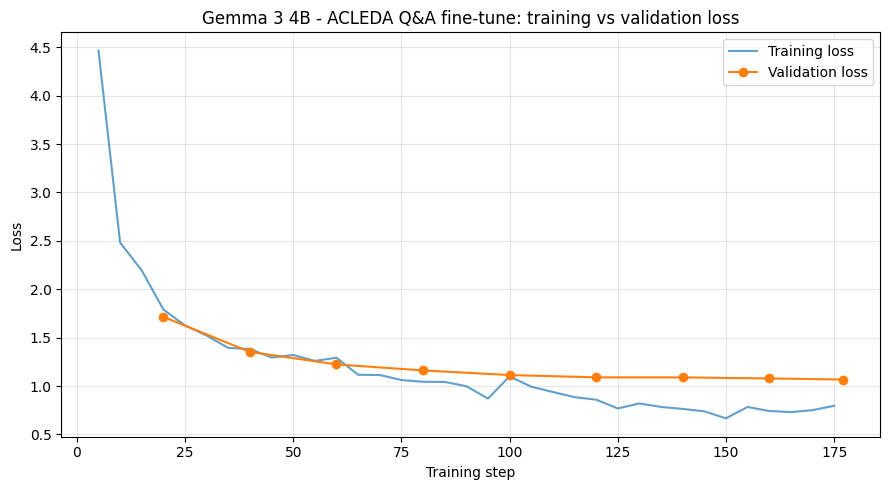

In [21]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_steps = [h["step"] for h in history if "loss" in h]
train_loss = [h["loss"] for h in history if "loss" in h]
eval_steps = [h["step"] for h in history if "eval_loss" in h]
eval_loss = [h["eval_loss"] for h in history if "eval_loss" in h]
print(f"Logged train points: {len(train_loss)}, eval points: {len(eval_loss)}")
print(f"First train loss: {train_loss[0]:.4f} -> last train loss: {train_loss[-1]:.4f}")
if eval_loss:
    print(f"First eval loss: {eval_loss[0]:.4f} -> best eval loss: {min(eval_loss):.4f} "
          f"-> last eval loss: {eval_loss[-1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(train_steps, train_loss, label="Training loss", alpha=0.7)
if eval_loss:
    plt.plot(eval_steps, eval_loss, marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Gemma 3 4B - ACLEDA Q&A fine-tune: training vs validation loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [22]:
# Automatic first reading of the curves — always check the plot too, not just these numbers.
if eval_loss:
    train_drop = train_loss[0] - train_loss[-1]
    eval_drop = eval_loss[0] - eval_loss[-1]
    gap = eval_loss[-1] - train_loss[-1]
    best_step = eval_steps[eval_loss.index(min(eval_loss))]
    print(f"Train loss fell by {train_drop:.2f}; validation loss fell by {eval_drop:.2f}.")
    print(f"Final gap (val - train): {gap:.2f}. Best validation loss {min(eval_loss):.4f} at step {best_step}.")
    if eval_drop > 0 and gap < 0.5:
        print("Reading: learning well - both losses fell and the gap is small. "
              "The model generalises to unseen ACLEDA questions.")
    elif eval_loss[-1] > eval_loss[0] or gap > 1.0:
        print("Reading: possible OVERFITTING - validation loss stopped falling (or rose) "
              "while training loss kept falling.")
        print("Try: fewer epochs, lower LoRA r, higher weight decay, or more data.")
    elif train_loss[-1] > 1.0 and eval_loss[-1] > 1.0:
        print("Reading: possible UNDERFITTING - both losses are still high.")
        print("Try: more epochs, higher learning rate, or higher LoRA r.")
    else:
        print("Reading: mixed - look at the shape of the curve in the plot above before deciding.")
else:
    print("No validation loss was logged - check eval_strategy / eval_steps in CONFIG.")

Train loss fell by 3.67; validation loss fell by 0.65.
Final gap (val - train): 0.27. Best validation loss 1.0671 at step 177.
Reading: learning well - both losses fell and the gap is small. The model generalises to unseen ACLEDA questions.


## §6 — Inference after training: base vs fine-tuned

Same 3 questions, same greedy decoding as §3 — the only thing that changed is the training. Read the three rows per question: **GOLD** (the dataset answer), **BASE** (before training), **TUNED** (after training).

In [23]:
from unsloth import FastModel
FastModel.for_inference(model)  # 2x faster inference; call this only AFTER training

gold = {p["input"]: p["output"] for p in val_pairs}
for q in TEST_QUESTIONS:
    tuned = generate_answer(q)
    print("Q:", q)
    print("GOLD:", gold[q][:300])
    print("BASE:", BASELINE_OUTPUTS[q][:300])
    print("TUNED:", tuned[:300])
    print("-" * 80)

Q: តើអ៉ីអនកាតម៉ូបាលគឺជាអ្វី
GOLD: អ៉ីអន​កាត​ម៉ូបាល គឺជា​កម្មវិធី​ទូរស័ព្ទ​ដើម្បី​ផ្តល់​ភាព​ងាយស្រួល​ដល់​អ្នក​ប្រើប្រាស់​អ៉ីអនកាត។ វា​អនុញ្ញាត​អោយ អ្នក​ប្រើប្រាស់​អ៉ីអនកាត អាច​គ្រប់គ្រង​អ៉ីអនកាត​របស់​ពួកគាត់ ក៏​ដូចជា​ធ្វើ​ការទូទាត់​ទំនិញ​តាមរយៈ ស្កេន ធូ ផេ។
BASE: អ៉ីអនកាតម៉ូបាល (eNKey Mobile) គឺជាបច្ចេកវិជ្ជារបស់ក្រុមហ៊ុន Cambodian e-Government Authority (eGA) ដែលមានគោលប tujuan យ៉ាងសំខាន់គឺ ធ្វើឱ្យការប្រើប្រាស់ប័ណ្ណអេឡិចត្រូនិច (e-ID) ង่ายស្រួល និង సుវត្តិសម្រាប់ប្រជាជនកម្ពុជា។ 

ខាងក្រោមនេះជាការបកស្រាយយ៉ាងវែងឆ្កួតអំពីអ៉ីអនកាតម៉ូបាល:

**1. គោលបំណង និង មុខងារ
TUNED: អ៉ីអនកាតម៉ូបាល គឺជាកាតអេឡិចត្រូនិកមួយប្រភេទ ដែលមានលក្ខណៈពិសេស អាចធ្វើប្រតិបត្តិការទូទាត់តាមរយៈទូរស័ព្ទដៃ គ្រប់ប្រភេទ ក្នុងទំហំទឹកប្រាក់ និងចំនួនប្រតិបត្តិការផ្សេងៗ តាមតម្រូវការ ដោយមិនចាំបាច់ប្រើប្រាស់ទូរស័ព្ទដៃនោះទេ។
--------------------------------------------------------------------------------
Q: តើសេវាភតិសន្យាហិរញ្ញវត្ថុមានប្រភេទរូបិយប័ណ្ណអ្វីខ្លះ
GOLD: សេវាភតិសន្យាហិរញ្ញវត្ថុត្រូវបានផ្តល់ជូនអតិថិជនជារូបិយប័ណ្ណ ប្រាក់រៀល 

You can also use a `TextStreamer` for continuous inference — see the generation token by token instead of waiting for the whole answer. Gemma-3's recommended sampling settings are `temperature = 1.0, top_p = 0.95, top_k = 64`.

In [24]:
messages = [{"role": "user", "content": TEST_QUESTIONS[0]}]
text = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors="pt").to("cuda"),
    max_new_tokens=256,
    temperature=1.0, top_p=0.95, top_k=64,
    streamer=TextStreamer(tokenizer, skip_prompt=True),
)

អ៉ីអនកាតម៉ូបាល គឺជាសេវាផ្តល់កាតអេឡិចត្រូនិច មួយប្រភេទដល់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី មកផ្តល់ជូនអតិថិជនដែលជាកម្មករនិយោជិត និងបុគ្គលិករបស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី ជាសេវាបញ្ញើតាមរយៈទូរស័ព្ទចល័ត រួមទាំងអាចផ្ទេរប្រាក់ក្នុង និងក្រៅប្រទេស តាមរយៈលេខទូរស័ព្ទ ឬទូរស័ព្ទដៃតាមរយៈទំហំទឹកប្រាក់ដែលអាចស្នើសុំបាន និងការកំណត់ទំហំទឹកប្រាក់ជូនទៅតាមប្រភេទកាត។ ដូចនេះ សមាជិក ឬម្ចាស់កាតមិនចាំបាច់រាយការណ៍អំពីប្រតិបត្តិការប្រើប្រាស់ ឬផ្ទេរប្រាក់តាមរយៈលេខទូរស័ព្ទនោះទេ។<end_of_turn>


### Two genuinely new questions (not in the dataset)

These test generalisation: the model has never seen these exact wordings. Expect weaker, sometimes wrong, answers — a fine-tuned model on 519 pairs learns the *style and the common facts*, not the whole bank. If it invents a fee or a limit, that is hallucination: note it in your write-up, do not hide it.

In [25]:
NEW_QUESTIONS = [
    "តើខ្ញុំអាចស្នើសុំប័ណ្ណឥណពន្ធអេស៊ីលីដា នៅសាខាណាមួយ?",
    "តើប័ណ្ណអេស៊ីលីដា អាចប្រើនៅក្រៅប្រទេសបានដែរឬទេ?",
]
for q in NEW_QUESTIONS:
    print("Q:", q)
    print("TUNED:", generate_answer(q))
    print()

Q: តើខ្ញុំអាចស្នើសុំប័ណ្ណឥណពន្ធអេស៊ីលីដា នៅសាខាណាមួយ?
TUNED: លោក-អ្នកអាចស្នើសុំប័ណ្ណឥណពន្ធអេស៊ីលីដា តាមរយៈការស្នើសុំនៅសាខាណាមួយដែលនៅជិតលោក-អ្នកបំផុត។

Q: តើប័ណ្ណអេស៊ីលីដា អាចប្រើនៅក្រៅប្រទេសបានដែរឬទេ?
TUNED: ប័ណ្ណអេស៊ីលីដា អាចប្រើនៅក្រៅប្រទេសបាន។



## §7 — Saving and pushing to Hugging Face

**LoRA adapter vs merged model — which to upload?**

| | LoRA adapter (`gemma-3-4b-aclede-qa-lora`) | Merged model (`gemma-3-4b-aclede-qa-merged`) |
|---|---|---|
| Size | Small (tens of MB) | ~8 GB (16-bit) |
| Needs base model to run? | Yes — load base `unsloth/gemma-3-4b-it`, then load the adapter | No — standalone |
| Upload time | Seconds–minutes | Much longer |
| Recommended for this homework | **Yes — upload this one** | Optional, if you want a one-file model |

**Before uploading:** accept the Gemma licence at https://huggingface.co/google/gemma-3-4b-it, create a token with **write** permission at https://huggingface.co/settings/tokens, and set `hf_username` in `CONFIG`. Never paste your token into a shared notebook — the login cell below asks for it interactively.

In [26]:
# Local save — LoRA adapter only (small). This does NOT upload anything.
model.save_pretrained(CONFIG["lora_dir"])
tokenizer.save_pretrained(CONFIG["lora_dir"])
print(f"Saved LoRA adapter + tokenizer to ./{CONFIG['lora_dir']}/")
print("This saves ONLY the LoRA adapter, not the full 4B model.")

Unsloth: Restored added_tokens_decoder metadata in gemma-3-4b-aclede-qa-lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma-3-4b-aclede-qa-lora.


Saved LoRA adapter + tokenizer to ./gemma-3-4b-aclede-qa-lora/
This saves ONLY the LoRA adapter, not the full 4B model.


In [38]:
# Log in to Hugging Face (paste your token when asked).
from huggingface_hub import notebook_login
notebook_login()

In [39]:
# Push the LoRA adapter to your Hugging Face account.
if CONFIG["push_to_hub"]:
    repo = f"{CONFIG['hf_username']}/{CONFIG['hf_repo_lora']}"
    model.push_to_hub(repo)
    tokenizer.push_to_hub(repo)
    print(f"Pushed LoRA adapter to https://huggingface.co/{repo}")
else:
    print("push_to_hub is False in CONFIG - set it to True (and set hf_username) to upload.")

README.md:   0%|          | 0.00/579 [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 60.6kB /  119MB            

Validating                    :           |   0%            

Saved model to https://huggingface.co/mondolreal/gemma-3-4b-it-aclede-qa-lora


... (3 outputs left out)

  ...pb0tt4520/tokenizer.model: 100%|##########| 4.69MB / 4.69MB            

  ...mpb0tt4520/tokenizer.json:  72%|#######1  | 23.9MB / 33.4MB            

Validating                    :           |   0%            

Pushed LoRA adapter to https://huggingface.co/mondolreal/gemma-3-4b-it-aclede-qa-lora


In [29]:
# Optional: save the FULL merged model locally (~8 GB, takes several minutes).
SAVE_MERGED = False  # set to True to run this cell
if SAVE_MERGED:
    model.save_pretrained_merged(CONFIG["merged_dir"], tokenizer, save_method="merged_16bit")
    print(f"Saved merged model to ./{CONFIG['merged_dir']}/")
else:
    print("SAVE_MERGED is False - merged save skipped.")

SAVE_MERGED is False - merged save skipped.


In [30]:
# Optional: push the merged model to Hugging Face.
if CONFIG["push_to_hub"] and SAVE_MERGED:
    repo = f"{CONFIG['hf_username']}/{CONFIG['hf_repo_merged']}"
    model.push_to_hub_merged(repo, tokenizer, save_method="merged_16bit")
    print(f"Pushed merged model to https://huggingface.co/{repo}")
else:
    print("Merged push skipped - needs push_to_hub = True in CONFIG and SAVE_MERGED = True above.")

Merged push skipped - needs push_to_hub = True in CONFIG and SAVE_MERGED = True above.


In [31]:
# Optional: save as GGUF (for llama.cpp / Ollama). Q8_0 is the recommended quantisation here.
SAVE_GGUF = False  # set to True to run this cell
if SAVE_GGUF:
    model.save_pretrained_gguf(CONFIG["merged_dir"], quantization_type="Q8_0")
    print("Saved GGUF model.")
else:
    print("SAVE_GGUF is False - GGUF save skipped.")

SAVE_GGUF is False - GGUF save skipped.


### How to use the uploaded model later

```python
from unsloth import FastModel
model, tokenizer = FastModel.from_pretrained(
    model_name="YOUR_HF_USERNAME/gemma-3-4b-it-aclede-qa-lora",  # LoRA adapter repo
    max_seq_length=2048,
    load_in_4bit=True,
)
# then ask questions exactly as in §3 / §6
```

If you uploaded the **merged** model instead, use its repo name and it loads standalone (no separate adapter step).

## §8 — Homework write-up (fill in after your run)

### Comparison: old dataset vs new dataset

| | Old run (original notebook) | New run (this notebook — fill in) |
|---|---|---|
| Dataset | `data_kh.csv` — robot commands, Khmer → JSON actions | `dataasilida_cleaned.csv` — ACLEDA Q&A, Khmer → Khmer answers |
| Rows | 2,930 | **519** (521 repaired − 2 exact duplicates) |
| Train / val | No validation split; `eval_dataset = None` | **470 train / 49 val**, grouped by question |
| Output type | Short JSON, e.g. `{'action':'move', ...}` | Long natural answers, median 231 chars |
| Steps | 60 (`max_steps=60`, ~16% of the data seen) | 3 epochs = **174 steps** |
| Training loss | **5.379 → 0.575** | First → last: ____ → ____ |
| Validation loss | **None logged** | First → best → last: ____ → ____ → ____ |
| Overfitting? | Could not tell (no val loss) | Your reading from §5: ____ |
| Training time | ~8 min, peak 6.31 GB (T4) | ____ min, peak ____ GB |
| Before/after answers | Only after-training inference | §3 BASE vs §6 TUNED: ____ |

### Questions to answer in your submission
1. **Workflow:** in your own words, what does each step (base model → dataset → LoRA → SFT → evaluation → push) do, and what would break if you skipped dataset preparation?
2. **Configuration:** which hyperparameter did you change (or would you change first), why, and what happened to the loss curve and the answers?
3. **Loss analysis:** paste your `loss_curve.png` and describe it — did both losses fall? Where did validation loss stop improving? Overfitting, underfitting, or learning well — and what is your evidence?
4. **Experiment:** for the 3 test questions, did the tuned model beat the base model? Give one example where it clearly improved and one where it still failed (wrong fact, hallucinated number, or cut-off answer).

### Checklist before submitting
- [ ] Notebook runs top to bottom without errors (restart + Run All).
- [ ] `loss_curve.png` exists and both curves are visible.
- [ ] §6 comparison is filled in (BASE vs TUNED vs GOLD).
- [ ] LoRA adapter pushed to Hugging Face (link pasted in your report) — or, if not pushed, the local `gemma-3-4b-aclede-qa-lora` folder is saved.
- [ ] The comparison table above is filled in with **your** numbers, not the example numbers.

### One-sentence takeaway
Fine-tuning did not teach Gemma 3 the Khmer language or how to chat — it taught a model that already chats to answer **ACLEDA questions in ACLEDA's wording**, and the validation loss (not the training loss) is what tells you whether it actually learned that.

## Next step

If the validation curve says **overfitting**, try `num_train_epochs = 2` or `lora_r = 8` and compare. If it says **underfitting**, try `num_train_epochs = 4` or `learning_rate = 3e-4`. Change **one** thing, re-run, and put the new curve next to the old one — that comparison is the strongest part of this homework.